# 1. FROSTOL kill surface across the Black Sea wheat belt

This notebook runs WOFOST with the FROSTOL winter-kill submodule in every wheat cell of the Black Sea basin for the 2024/25 and 2025/26 seasons. Each cell records its season kill fraction `RF_FROST_T`, and cells are then weighted by CROPGRIDS wheat area up to oblast, country and basin. It produces the parameter set in paper Table 1, paper Figure 1 (diagnostics for one Rostov cell) and the GeoJSON behind paper Figure 2 (the kill surface map).

## Set-up

**Weather.** NASA POWER (MERRA-2), fetched per cell through PCSE. Its native resolution is 0.5° × 0.625°, so the 0.5° grid is the finest that makes sense. PCSE caches each response on disk. `fix_winterkill` caps the request end date because the POWER feed lags by about two weeks.

**Snow.** SnowMAUS (`ISNOWSRC = 1`), as in MOCCCASIN. It builds snow depth from TMIN, TMAX and rain, because neither the Russian station network nor POWER provides a usable daily snow depth. Parameters follow Trnka et al. (2010, Table 2a) converted from mm to cm (`RMELT` 0.42 mm to 0.042 cm, `SCTHRESHOLD` 20 mm to 2.0 cm), with the Tula-calibrated `SNOWDENSITY = 0.164` (MOCCCASIN D5.3, section 4.2).

**FROSTOL and crown temperature.** MOCCCASIN calibration for Russian winter wheat, with `LT50C = −18 °C`, `KILLCF = 1.0189`, `CROWNTMPA/B = 0.2/0.5` and `FROSTOL_SDMAX = 12.5 cm`. Hardening and dehardening rates stay at the FROSTOL defaults (Bergjord et al., 2008).

**Reading the signal.** `RF_FROST_T` is read as a spatial pattern and a ranking, not as a literal kill percentage, because the calibration comes from Russian cultivars. Russia holds about two thirds of the wheat area in the grid. Ukraine, Romania and Bulgaria are genotype extrapolation and are shown for context only.

**Aggregation.** Kill is computed per cell and then weighted by wheat area. Averaging the weather first would smooth away the cold extremes that drive the nonlinear kill function (Hogan & Schlenker, 2024). Occupied or contested Ukrainian regions (Donetsk, Luhansk, Zaporizhzhia, Kherson, Crimea and Sevastopol) are dropped.

**Season window.** Sowing on 1 October and harvest on 15 May. POWER occasionally drops single days, so gaps of up to 5 days are filled by persistence (`n_filled` counts them). A season stops before any longer gap rather than inventing weather (`end_used` records where).

**Validation.** `RF_FROST_T` has not been checked against Rosstat yields or sown-versus-harvested area. Treat it as a model output, not a validated yield-loss estimate.

## Inputs

- `data/fetch_points_0.5deg_labeled.csv`, the wheat cells (pid, lon, lat, wheat_ha, country, oblast, note), built with `functions/build_fetch_points.py` and labelled with `functions/join_oblasts.py`
- `data/generic_medium.soil`
- `functions/fix_winterkill.py`, imported once before any PCSE engine is built

Run from the repository root.

In [1]:
import sys, time, json, math, copy
import datetime as dt
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
import pcse

ROOT   = Path.cwd()                    # run from the repository root
DATA   = ROOT / "data"
OUT    = ROOT / "output"
FIGDIR = OUT / "figures"
FIGDIR.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(ROOT / "functions"))
import fix_winterkill                  # patches PCSE 6.0.12; import once, before any Engine

from pcse.engine import Engine
from pcse.base import ParameterProvider
from pcse.input import (YAMLCropDataProvider, CABOFileReader, WOFOST72SiteDataProvider,
                        NASAPowerWeatherDataProvider)
print("pcse:", pcse.__version__)

[fix_winterkill] patch applied (PGASS/PMRES locals + REALLOC published)
[fix_winterkill] _on_CROP_FINISH signature aligned
[fix_winterkill] NASA POWER end-date capped to today-30d
[fix_winterkill] RAIN range loosened to (0, 100) cm/day for NASA POWER outliers
pcse: 6.0.12


In [2]:
# --- Fixed model inputs, parameter values as in paper Table 1 ---------------------
soil_file = DATA / "generic_medium.soil"
assert soil_file.exists(), f"soil file not found at {soil_file}"

crop = YAMLCropDataProvider(); crop.set_active_crop("wheat", "Winter_wheat_101")
soildata = CABOFileReader(soil_file)
sitedata = WOFOST72SiteDataProvider(WAV=15)

# FROSTOL Russia + crown (MOCCCASIN Tula) + SnowMAUS (ISNOWSRC=1). Provenance is in the intro.
frost_and_snow = {
    # FROSTOL rates at defaults (D5.3); Russia LT50C / crown / KILLCF adjusted
    "FROSTOL_H": 0.0093, "FROSTOL_D": 2.7e-05, "FROSTOL_S": 1.910, "FROSTOL_R": 0.541,
    "FROSTOL_KILLCF": 1.0189, "FROSTOL_SDBASE": 0.0, "FROSTOL_SDMAX": 12.5,
    "LT50C": -18.0, "LT50I": -4.01, "CROWNTMPA": 0.2, "CROWNTMPB": 0.5,
    # SnowMAUS -- Trnka (2010) Table 2a in cm + MOCCCASIN snow density (D5.3 sec 4.2)
    "TMINACCU1": 0.0, "TMINACCU2": -6.0, "TMINCRIT": -12.0, "TMAXCRIT": 5.0,
    "RMELT": 0.042,        # 0.42 mm/C/day -> cm
    "SCTHRESHOLD": 2.0,    # 20 mm -> cm
    "SNOWDENSITY": 0.164,  # cm_water/cm_snow (Tula-calibrated)
    "SWEDEPTHI": 0.0,      # no snow at autumn sowing
    "ISNOWSRC": 1,         # 1 = SIMULATED snow (SnowMAUS). POWER carries no snow field.
}

def make_params(extra=None):
    p = ParameterProvider(cropdata=crop, soildata=soildata, sitedata=sitedata)
    for k, v in {**frost_and_snow, **(extra or {})}.items():
        p.set_override(k, v, check=False)
    return p

In [3]:
# --- Configuration and wheat-cell selection ---------------------------------------
SEASONS          = [2024, 2025]     # sowing years -> 2024/25 and 2025/26
SEASON_END_MMDD  = "05-15"          # intended harvest in y0+1; capped to available weather at run time

FETCH_CSV        = DATA / "fetch_points_0.5deg_labeled.csv"
INCLUDE_OCCUPIED = False            # drop contested regions (unknowable weights); True keeps them
WHEAT_FRAC_MIN   = 0.10             # keep only cells where wheat covers >= this fraction of the cell area
GRID_STRIDE_DEG  = 0.5              # cell size for the wheat-fraction denominator (match the fetch grid)
CHECKPOINT_EVERY = 100

points = pd.read_csv(FETCH_CSV)

# Crimea/Sevastopol are contested but are NOT tagged "occupied" in the source CSV
# (only the four mainland oblasts Donetsk/Luhansk/Zaporizhzhia/Kherson are), so
# without this they run as normal calibrated cells. Re-tag them as "occupied" so
# INCLUDE_OCCUPIED governs every contested region uniformly. Matched on the oblast
# name, with a Crimean-peninsula bounding box as a fallback in case the label differs.
if "note" in points.columns:
    _crimea_names = {"crimea", "krym", "krim", "respublika krym",
                     "avtonomna respublika krym", "autonomous republic of crimea",
                     "sevastopol", "sevastopol'", "sevastopol city", "gorod sevastopol"}
    _ob = (points["oblast"].astype(str).str.strip().str.lower()
           if "oblast" in points.columns else pd.Series("", index=points.index))
    _crimea = _ob.isin(_crimea_names) | (
        points["lon"].between(32.4, 36.8) & points["lat"].between(44.3, 46.25))
    points.loc[_crimea, "note"] = "occupied"
    print(f"flagged {int(_crimea.sum())} Crimea/Sevastopol cells as contested")

if (not INCLUDE_OCCUPIED) and "note" in points.columns:
    n = len(points); points = points[points["note"] != "occupied"].copy()
    print(f"dropped {n - len(points)} occupied/contested cells; {len(points)} remain")

# --- wheat-density mask: run only where wheat is a material land use ------
# CROPGRIDS gives wheat area per cell (wheat_ha). Dividing by the cell's own area
# turns that into the fraction of the 0.5 deg cell under wheat. An absolute floor
# (the min_ha in build_fetch_points.py) admits sliver-of-valley-wheat cells on the
# Caucasus/Carpathian/Balkan fringe, whose 0.5 deg mean weather does not represent
# that sliver; a fractional floor is scale-consistent across latitude and isolates
# wheat-dominated cells. wheat_frac is kept as a column so it can also drive marker
# size in QGIS.
_R    = 6371.0                                   # km, spherical earth
_dlon = np.radians(GRID_STRIDE_DEG)
_ha   = (_R**2 * _dlon *
         (np.sin(np.radians(points["lat"] + GRID_STRIDE_DEG / 2)) -
          np.sin(np.radians(points["lat"] - GRID_STRIDE_DEG / 2)))) * 100.0   # km^2 -> ha
points["wheat_frac"] = points["wheat_ha"] / _ha

print("\nwheat-fraction threshold sweep (cells kept / wheat Mha kept):")
for _thr in (0.0, 0.05, 0.10, 0.15, 0.20, 0.30):
    _k = points["wheat_frac"] >= _thr
    print(f"  >= {_thr:>4.0%}: {int(_k.sum()):4d} cells   {points.loc[_k, 'wheat_ha'].sum() / 1e6:5.2f} Mha")

n = len(points)
points = points[points["wheat_frac"] >= WHEAT_FRAC_MIN].copy()
print(f"\nwheat-fraction mask >= {WHEAT_FRAC_MIN:.0%}: dropped {n - len(points)} thin-wheat cells; {len(points)} remain")

points = points.reset_index(drop=True)
print(f"{len(points)} cells x {len(SEASONS)} seasons = {len(points) * len(SEASONS)} runs")
print(f"first run is one POWER API call per cell (~{len(points) * 3 // 60}-{len(points) * 5 // 60} min); "
      f"pcse caches to disk, same-day re-runs are fast")

def agro_for_season(y0, end_date, crop_name="wheat", variety="Winter_wheat_101"):
    # end_date is a 'YYYY-MM-DD' string, capped to available weather in run_cell_season
    return yaml.safe_load(f"""
Version: 1.0
AgroManagement:
- {y0}-10-01:
    CropCalendar:
        crop_name: {crop_name}
        variety_name: {variety}
        crop_start_date: {y0}-10-01
        crop_start_type: sowing
        crop_end_date: {end_date}
        crop_end_type: harvest
        max_duration: 330
    TimedEvents: null
    StateEvents: null
""")["AgroManagement"]

flagged 18 Crimea/Sevastopol cells as contested
dropped 66 occupied/contested cells; 763 remain

wheat-fraction threshold sweep (cells kept / wheat Mha kept):
  >=   0%:  763 cells   19.25 Mha
  >=   5%:  602 cells   18.57 Mha
  >=  10%:  477 cells   16.64 Mha
  >=  15%:  256 cells   11.12 Mha
  >=  20%:  114 cells    6.22 Mha
  >=  30%:   19 cells    1.48 Mha

wheat-fraction mask >= 10%: dropped 286 thin-wheat cells; 477 remain
477 cells x 2 seasons = 954 runs
first run is one POWER API call per cell (~23-39 min); pcse caches to disk, same-day re-runs are fast


In [4]:
# --- NASA POWER weather, one fresh provider per cell ------------------------------
# PCSE caches each POWER response on disk, so reruns skip the API. Providers are not
# kept in memory: each holds about 40 years of daily weather, and the grid loop visits
# every cell once with both seasons in the same iteration.
def get_power_wdp(lat, lon):
    return NASAPowerWeatherDataProvider(latitude=lat, longitude=lon)

In [5]:
# --- One wheat cell, one season: RF_FROST_T and winter extremes -------------------# POWER drops scattered days where a variable (usually radiation) is missing. Gaps of up
# to MAX_FILL consecutive days are filled by persistence so the crop can run. A season
# stops before any longer or open-ended gap rather than inventing weather, and is
# harvested at the last usable day. `end_used` and `n_filled` record both.
WIN_MONTHS = [12, 1, 2, 3]
MAX_FILL   = 5                                  # longest gap (consecutive days) we persistence-fill
_END_MM, _END_DD = map(int, SEASON_END_MMDD.split("-"))

def _prepare_season(wdp, sow, hard_end):
    """Persistence-fill gaps <= MAX_FILL days; stop before any longer/open gap.
       Returns (last_usable_date, n_filled)."""
    present = {k[0] for k in wdp.store}
    if sow not in present:
        return None, 0
    d, filled = sow, 0
    while d < hard_end:
        nxt = d + dt.timedelta(days=1)
        if nxt in present:
            d = nxt; continue
        j = nxt                                 # measure the gap length
        while j <= hard_end and j not in present:
            j += dt.timedelta(days=1)
        if j > hard_end or (j - nxt).days > MAX_FILL:
            break                               # long or open-ended gap -> stop at d
        base = wdp(d)                           # fill the short gap by persistence
        g = nxt
        while g < j:
            wdc = copy.deepcopy(base); wdc.DAY = g
            wdp._store_WeatherDataContainer(wdc, g); present.add(g); filled += 1
            g += dt.timedelta(days=1)
        d = j - dt.timedelta(days=1)
    return d, filled

def run_cell_season(wdp, y0):
    sow      = dt.date(y0, 10, 1)
    hard_end = min(dt.date(y0 + 1, _END_MM, _END_DD), wdp.last_date)   # 15 May or data end
    end, n_filled = _prepare_season(wdp, sow, hard_end)
    if end is None or (end - sow).days < 90:
        raise RuntimeError(f"insufficient continuous weather from sowing {sow} (last={wdp.last_date})")
    wf = Engine(make_params(), wdp, agro_for_season(y0, end.strftime("%Y-%m-%d")),
                config="Wofost_winterkill.conf")
    wf.run_till_terminate()
    out = pd.DataFrame(wf.get_output()).set_index("day"); out.index = pd.to_datetime(out.index)
    win = out[out.index.month.isin(WIN_MONTHS)]
    return {"RF_FROST_T": float(out["RF_FROST_T"].iloc[-1]),
            "LT50_min":  float(out["LT50T"].min()),
            "CROWN_min": float(win["TMIN_CROWN"].min()),
            "SNOW_max":  float(win["SNOWDEPTH"].max()),
            "end_used":  end.strftime("%Y-%m-%d"),
            "n_filled":  n_filled}

In [6]:
# --- POWER data gaps for the Rostov cell since 1 October 2025 ---------------------
w = get_power_wdp(47.2, 40.8)
present = {k[0] for k in w.store}
lo, hi = dt.date(2025, 10, 1), w.last_date
missing = [lo + dt.timedelta(d) for d in range((hi - lo).days + 1)
           if (lo + dt.timedelta(d)) not in present]
print("first:", w.first_date, "last:", w.last_date, "| present days:", len(present))
print(f"missing days {lo}..{hi}: {len(missing)}")
print(missing[:40])

first: 1984-01-01 last: 2026-09-17 | present days: 15600
missing days 2025-10-01..2026-09-17: 0
[]


2025/26  RF_FROST_T=0.272  (end 2026-05-15, 0 filled)

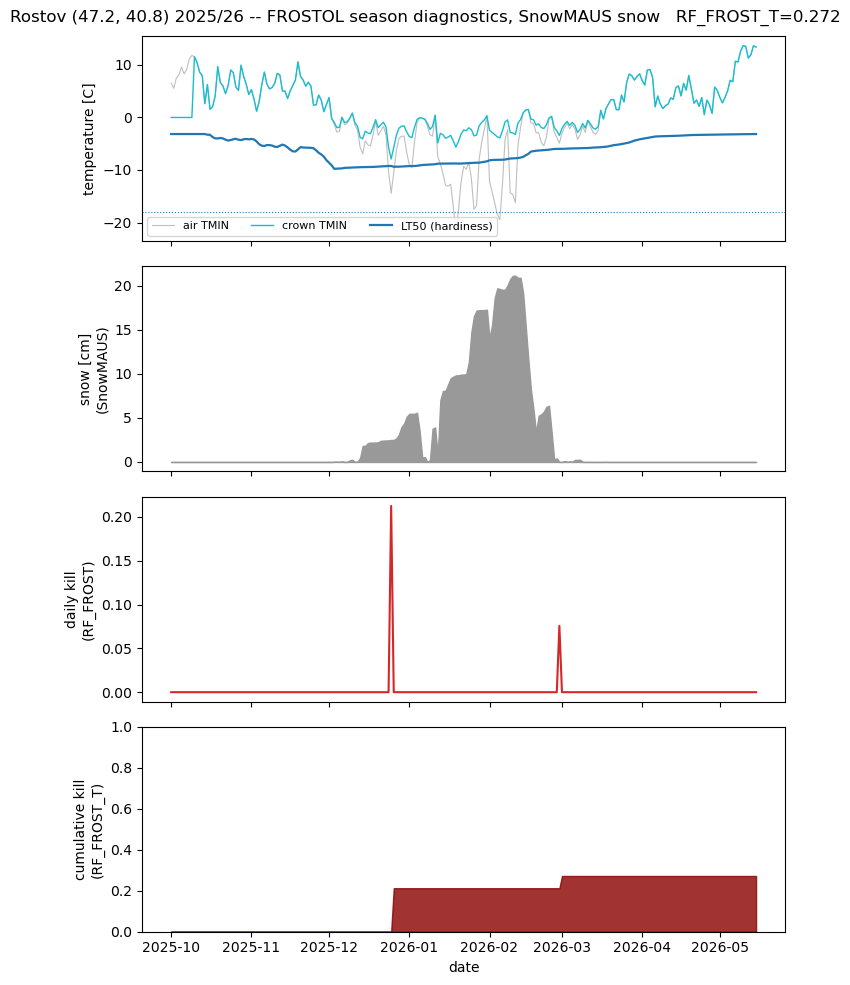

In [7]:
# --- Paper Figure 1: FROSTOL diagnostics for the Rostov cell, 2025/26 -------------
LAT, LON, PLACE = 47.2, 40.8, "Rostov"
Y0 = 2025                                            # 2025/26 season

def _run_cell(lat, lon, y0):
    """One cell, one season, with full daily output and air TMIN for plotting."""
    wdp = get_power_wdp(lat, lon)
    sow      = dt.date(y0, 10, 1)
    hard_end = min(dt.date(y0 + 1, _END_MM, _END_DD), wdp.last_date)
    end, n_filled = _prepare_season(wdp, sow, hard_end)
    if end is None or (end - sow).days < 90:
        raise RuntimeError(f"insufficient continuous weather from sowing {sow} (last={wdp.last_date})")
    wf = Engine(make_params(), wdp, agro_for_season(y0, end.strftime("%Y-%m-%d")),
                config="Wofost_winterkill.conf")
    wf.run_till_terminate()
    out = pd.DataFrame(wf.get_output()).set_index("day"); out.index = pd.to_datetime(out.index)
    def _tmin(d):                              # air TMIN pulled from the provider over the run window
        try:    return wdp(d.date()).TMIN
        except Exception: return float("nan")
    air = pd.Series([_tmin(d) for d in out.index], index=out.index)
    return out, air, end, n_filled

out, air, end, n_filled = _run_cell(LAT, LON, Y0)
rf = float(out["RF_FROST_T"].iloc[-1])
print(f"{Y0}/{str(Y0+1)[2:]}  RF_FROST_T={rf:.3f}  (end {end}, {n_filled} filled)")

fig, ax = plt.subplots(4, 1, figsize=(7.5, 10), sharex=True)

ax[0].plot(out.index, air,               color="0.75",     lw=0.8, label="air TMIN")
ax[0].plot(out.index, out["TMIN_CROWN"], color="tab:cyan", lw=1.0, label="crown TMIN")
ax[0].plot(out.index, out["LT50T"],      color="tab:blue", lw=1.6, label="LT50 (hardiness)")
ax[0].axhline(-18.0, color="tab:blue", ls=":", lw=0.8)          # LT50C floor
ax[0].set_ylabel("temperature [C]")
ax[0].legend(loc="lower left", fontsize=8, ncol=3)

ax[1].fill_between(out.index, out["SNOWDEPTH"], color="0.6")
ax[1].set_ylabel("snow [cm]\n(SnowMAUS)")

ax[2].plot(out.index, out["RF_FROST"], color="tab:red")
ax[2].set_ylabel("daily kill\n(RF_FROST)")

ax[3].fill_between(out.index, out["RF_FROST_T"], color="darkred", alpha=0.8)
ax[3].set_ylim(0, 1)
ax[3].set_ylabel("cumulative kill\n(RF_FROST_T)")
ax[3].set_xlabel("date")

fig.suptitle(f"{PLACE} ({LAT}, {LON}) {Y0}/{str(Y0+1)[2:]} -- FROSTOL season diagnostics, "
             f"SnowMAUS snow   RF_FROST_T={rf:.3f}")
fig.tight_layout()
for e in ("pdf", "png"):
    fig.savefig(FIGDIR / f"fig1_rostov_frostol_2025_26.{e}", dpi=200, bbox_inches="tight")
plt.show()

In [8]:
# --- Run the grid: every wheat cell, both seasons ---------------------------------
# The first run makes one POWER request per cell (about 25 to 40 minutes). If the grid
# CSV already exists it is loaded instead. Delete it to force a fresh run.
GRID_CSV = OUT / "frostol_grid_power_snowmaus.csv"
PARTIAL  = OUT / "frostol_grid_power_snowmaus_partial.csv"

if GRID_CSV.exists():
    grid = pd.read_csv(GRID_CSV)
    print(f"loaded {GRID_CSV.relative_to(ROOT)}: {len(grid)} cell-seasons "
          f"({(grid['RF_FROST_T'] > 0).sum()} fired)")
else:
    results, t0 = [], time.time()
    for i, row in points.iterrows():
        try:
            wdp = get_power_wdp(row["lat"], row["lon"])
        except Exception as e:
            print(f"  {row['pid']} ({row['lon']},{row['lat']}) POWER FETCH FAILED: {str(e)[:70]}")
            continue
        for y0 in SEASONS:
            label = f"{y0}/{str(y0 + 1)[2:]}"
            try:
                r = run_cell_season(wdp, y0)
                r.update({"season": label, "pid": row["pid"], "lon": row["lon"], "lat": row["lat"],
                          "wheat_ha": row["wheat_ha"], "country": row["country"],
                          "oblast": row.get("oblast"), "note": row.get("note", "")})
                results.append(r)
            except Exception as e:
                print(f"  {row['pid']} {label} SKIPPED: {str(e)[:70]}")
        if (i + 1) % CHECKPOINT_EVERY == 0:
            pd.DataFrame(results).to_csv(PARTIAL, index=False)
            el = time.time() - t0
            print(f"  {i+1}/{len(points)} cells  ({el/(i+1):.1f}s/cell, {el/60:.0f} min elapsed)")

    grid = pd.DataFrame(results)
    grid.to_csv(GRID_CSV, index=False)
    print(f"\ndone: {len(grid)} cell-seasons in {(time.time()-t0)/60:.1f} min  "
          f"({(grid['RF_FROST_T']>0).sum()} fired)")

loaded output/frostol_grid_power_snowmaus.csv: 954 cell-seasons (831 fired)


In [9]:
# --- Area-weighted aggregation per season, applied to outputs not weather ---------
def wmean(d, value="RF_FROST_T", weight="wheat_ha"):
    w = d[weight]
    return float((d[value] * w).sum() / w.sum())

for s in sorted(grid["season"].unique()):
    g = grid[grid["season"] == s]
    print(f"\n===== {s} =====")
    print(f"BASIN area-weighted RF_FROST_T: {wmean(g):.4f}")
    by_country = g.groupby("country").apply(lambda d: pd.Series({
        "cells": len(d), "wheat_Mha": d["wheat_ha"].sum()/1e6,
        "RF_FROST_T_wtd": wmean(d), "RF_FROST_T_max": d["RF_FROST_T"].max()})).round(3)
    print(by_country.to_string())

by_oblast = grid.groupby(["season", "country", "oblast"]).apply(lambda d: pd.Series({
    "cells": len(d), "wheat_kha": d["wheat_ha"].sum()/1e3,
    "RF_FROST_T_wtd": wmean(d)})).round(3)
by_oblast.to_csv(OUT / "frostol_by_oblast_power_snowmaus.csv")
print("\nsaved output/frostol_by_oblast_power_snowmaus.csv")
by_oblast.sort_values("RF_FROST_T_wtd", ascending=False).head(20)


===== 2024/25 =====
BASIN area-weighted RF_FROST_T: 0.3145
         cells  wheat_Mha  RF_FROST_T_wtd  RF_FROST_T_max
country                                                  
BG        18.0      0.769           0.868           0.994
RO        26.0      1.075           0.616           0.773
RU       296.0     10.859           0.260           0.731
UA       137.0      3.936           0.275           0.742

===== 2025/26 =====
BASIN area-weighted RF_FROST_T: 0.3333
         cells  wheat_Mha  RF_FROST_T_wtd  RF_FROST_T_max
country                                                  
BG        18.0      0.769           0.388           0.877
RO        26.0      1.075           0.207           0.609
RU       296.0     10.859           0.375           0.993
UA       137.0      3.936           0.242           0.910

saved output/frostol_by_oblast_power_snowmaus.csv


cells  wheat_kha  RF_FROST_T_wtd
season  country oblast                                             
2024/25 BG      Haskovo              1.0     28.444           0.994
2025/26 RU      Adygey               1.0     42.081           0.992
2024/25 BG      Yambol               2.0    100.550           0.957
                Burgas               2.0     62.158           0.936
                Varna                2.0     84.864           0.917
                Targovishte          2.0     65.338           0.912
                Stara Zagora         2.0     91.688           0.878
2025/26 BG      Haskovo              1.0     28.444           0.877
        RU      Karachay-Cherkess    2.0     80.278           0.863
2024/25 BG      Dobrich              3.0    170.690           0.849
                Razgrad              1.0     49.551           0.819
2025/26 RU      Krasnodar           25.0   1260.810           0.786
2024/25 BG      Veliko Tarnovo       2.0     69.227           0.782
        RO      Constanta            1.0     79.006           0.773
                Dâmbovita            1.0     23.692           0.766
                Ilfov                1.0     37.152           0.729
                Vrancea              1.0     26.416           0.726
                Galati               1.0     42.524           0.726
2025/26 BG      Yambol               2.0    100.550           0.695
        RU      Stavropol'          26.0   1720.893           0.673

In [10]:
# --- Export the kill surface to GeoJSON, the source of paper Figure 2 -------------
def _safe(v):
    if v is None: return None
    if hasattr(v, "item"): v = v.item()
    if isinstance(v, float) and math.isnan(v): return None
    return v if isinstance(v, (int, float, str, bool)) else str(v)

for s in sorted(grid["season"].unique()):
    g = grid[grid["season"] == s]
    feats = []
    for _, r in g.iterrows():
        props = {k: _safe(r[k]) for k in g.columns if k not in ("lon", "lat")}
        feats.append({"type": "Feature",
                      "geometry": {"type": "Point", "coordinates": [float(r["lon"]), float(r["lat"])]},
                      "properties": props})
    fname = OUT / f"frostol_{s.replace('/', '_')}_power_snowmaus.geojson"
    with open(fname, "w") as f:
        json.dump({"type": "FeatureCollection", "features": feats}, f, indent=2)
    print(f"wrote {fname.relative_to(ROOT)}  ({len(feats)} cells)")

wrote output/frostol_2024_25_power_snowmaus.geojson  (477 cells)
wrote output/frostol_2025_26_power_snowmaus.geojson  (477 cells)


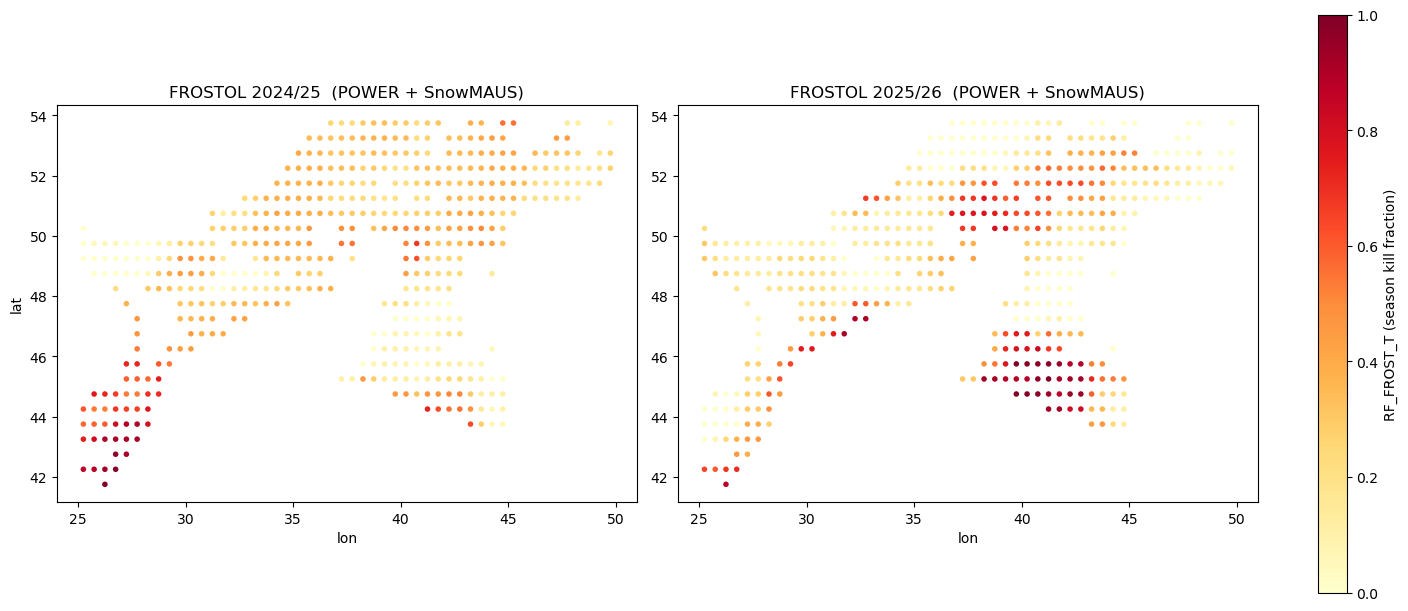

In [11]:
# --- Quick look at the kill surface (paper Figure 2 is the QGIS version) ----------
seasons = sorted(grid["season"].unique())
fig, axes = plt.subplots(1, len(seasons), figsize=(7*len(seasons), 6), squeeze=False,
                         layout="constrained")
sc = None
for ax, s in zip(axes[0], seasons):
    g = grid[grid["season"] == s]
    sc = ax.scatter(g["lon"], g["lat"], c=g["RF_FROST_T"], s=16,
                    cmap="YlOrRd", vmin=0, vmax=1, edgecolors="none")
    ax.set_title(f"FROSTOL {s}  (POWER + SnowMAUS)"); ax.set_xlabel("lon"); ax.set_aspect(1.4)
axes[0][0].set_ylabel("lat")
fig.colorbar(sc, ax=axes[0], label="RF_FROST_T (season kill fraction)", fraction=0.025)
plt.show()